In [51]:
import sys, os

sys.path.append(os.path.abspath(os.path.join('..')))

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error



In [53]:
from src.data import load_csv

df = load_csv("../data/hour.csv")

In [54]:
features = ['atemp', 'hum', 'windspeed']
X_mlr = df[features]

X_slr = df[['atemp']]


Y = df['cnt']

In [55]:
## splitting dataset

X_train_slr, X_test_slr, y_train, y_test = train_test_split(X_slr, Y, test_size=0.25, random_state=42)

X_train_mlr, X_test_mlr, _, _ = train_test_split(X_mlr, Y, test_size=0.25, random_state=42)

In [56]:
def make_slr():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ('scale', StandardScaler()),
        ("model", LinearRegression())
    ])

def make_mlr():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", LinearRegression())
    ])

In [57]:
def bias_variance(model_factory, X_train, X_test, y_train, y_test, repeats=100, seed=42):
    rng = np.random.default_rng(seed)
    predictions = []
    X_train = X_train.reset_index(drop=True)
    y_train = y_train.reset_index(drop=True)

    n = len(X_train)

    for _ in range(repeats):

        indices = rng.integers(0, n, size=n)

        X_boot = X_train.iloc[indices]
        y_boot = y_train.iloc[indices]

        model = model_factory()
        model.fit(X_boot, y_boot)

        predictions.append(model.predict(X_test))

    predictions = np.asarray(predictions)

    average_prediction = predictions.mean(axis=0)
    y_true = np.asarray(y_test)

    bias_squared_proxy = np.mean(
        (average_prediction - y_true) ** 2
    )

    predictions_variance = np.mean(
        np.var(predictions, axis=0, ddof=0)
    )

    average_model_mse = np.mean(
        (predictions - y_true[None, :]) ** 2
    )

    return {
        "Bias² proxy": bias_squared_proxy,
        "Prediction Variance": predictions_variance,
        "Average Test MSE": average_model_mse,
        "Mean Predictions": average_prediction,
        "All predictions": predictions
    }






In [58]:
slr_result = bias_variance(make_slr, X_train_slr, X_test_slr, y_train, y_test, repeats=100, seed=42)

mlr_result = bias_variance(make_mlr, X_train_mlr, X_test_mlr, y_train, y_test, repeats=100, seed=42)

In [59]:
results_df = pd.DataFrame({
    "SLR (atemp)":{
        key: slr_result[key]
        for key in [
            "Bias² proxy",
            "Prediction Variance",
            "Average Test MSE"
        ]
    },
    "MLR (atemp, hum, windspeed)":{
        key: mlr_result[key]
        for key in [
            "Bias² proxy",
            "Prediction Variance",
            "Average Test MSE"
        ]
    }
}).T

print("\nBIAS-VARIANCE EXPERIMENT: SLR vs MLR")
print("=" * 75)
print(results_df.round(2))
print(type(results_df))


BIAS-VARIANCE EXPERIMENT: SLR vs MLR
                             Bias² proxy  Prediction Variance  Average Test MSE
SLR (atemp)                     26875.69                 3.71          26879.40
MLR (atemp, hum, windspeed)     23924.43                 6.53          23930.96
<class 'pandas.core.frame.DataFrame'>


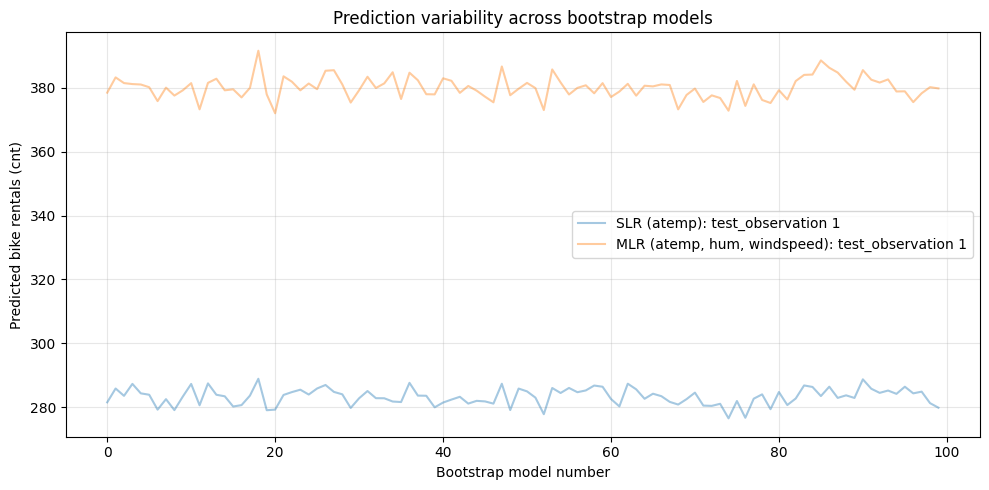

In [60]:
plt.figure(figsize=(10, 5))

for name, results_df in [
    ("SLR (atemp)", slr_result),
    ("MLR (atemp, hum, windspeed)", mlr_result)
]:
    all_preds = results_df["All predictions"]

    plt.plot(
        all_preds[:, 0],
        alpha= 0.4,
        label=f"{name}: test_observation 1"
    )

plt.xlabel("Bootstrap model number")
plt.ylabel("Predicted bike rentals (cnt)")
plt.title("Prediction variability across bootstrap models")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [61]:
print(type(results_df))

<class 'dict'>


In [62]:

results_df = pd.DataFrame({
    "SLR (atemp)": {
        "Bias² proxy": slr_result["Bias² proxy"],
        "Prediction Variance": slr_result["Prediction Variance"],
        "Average Test MSE": slr_result["Average Test MSE"]
    },
    "MLR (atemp, hum, windspeed)": {
        "Bias² proxy": mlr_result["Bias² proxy"],
        "Prediction Variance": mlr_result["Prediction Variance"],
        "Average Test MSE": mlr_result["Average Test MSE"]
    }
}).T

print(type(results_df))  # Should be pandas DataFrame
print(results_df)


<class 'pandas.core.frame.DataFrame'>
                              Bias² proxy  ...  Average Test MSE
SLR (atemp)                  26875.687006  ...      26879.395554
MLR (atemp, hum, windspeed)  23924.425697  ...      23930.958428

[2 rows x 3 columns]


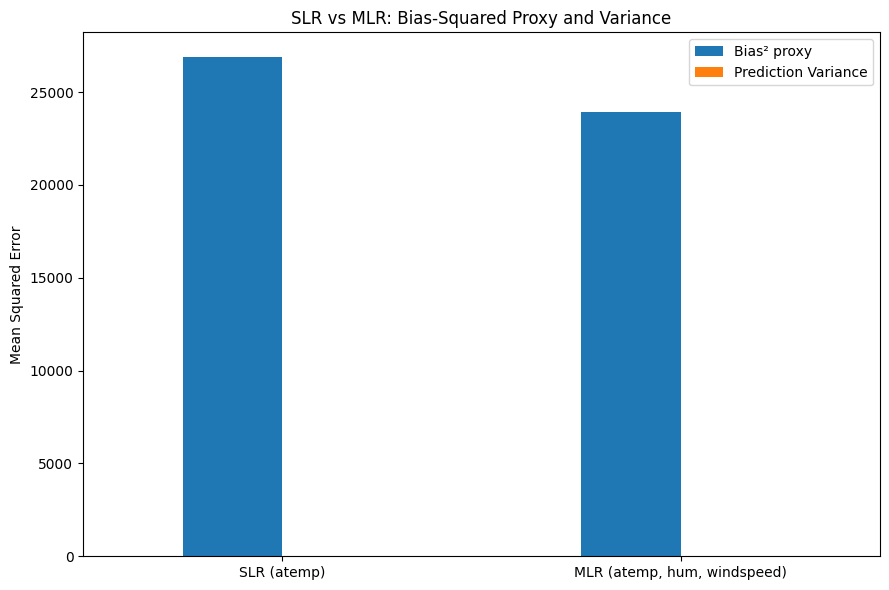

In [63]:
ax = results_df[
    ["Bias² proxy", "Prediction Variance"]
].plot(
    kind="bar",
    figsize=(9, 6)
)

ax.set_ylabel("Mean Squared Error")
ax.set_title("SLR vs MLR: Bias-Squared Proxy and Variance")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


   return {
        "Bias² proxy": bias_squared_proxy,
        "Prediction Variance": predictions_variance,
        "Average Test MSE": average_model_mse,
        "Mean Predictions": average_prediction,
        "All predictions": predictions
    }

In [64]:
## Polynomial Regression: model flexibility:

degrees = [1,2,3,4,5,6,7,8,9,10]
poly_results = []


for degree in degrees:

    def make_poly(d=degree):
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("poly", PolynomialFeatures(
                degree=d,
                include_bias=False
            )),
            ("scale", StandardScaler()),
            ("model", LinearRegression())
        ])

    result = bias_variance(
        make_poly,
        X_train_slr,
        X_test_slr,
        y_train,
        y_test,
        repeats=100,
        seed=42
    )

    poly_results.append({
        "Degree": degree,
        "Bias² proxy": result["Bias² proxy"],
        "Prediction Variance": result["Prediction Variance"],
        "Average Test MSE": result["Average Test MSE"]
    })

poly_df = pd.DataFrame(poly_results).set_index("Degree")

print("\nPOLYNOMIAL REGRESSION: MODEL FLEXIBILITY")
print("=" * 75)
print(poly_df.round(2))



POLYNOMIAL REGRESSION: MODEL FLEXIBILITY
        Bias² proxy  Prediction Variance  Average Test MSE
Degree                                                    
1          26875.69                 3.71          26879.40
2          26856.91                 5.31          26862.22
3          26797.31                 6.65          26803.97
4          26669.65                 7.24          26676.89
5          26634.47                10.03          26644.50
6          26606.16                11.12          26617.29
7          26555.81                19.39          26575.20
8          26545.27                30.11          26575.39
9          26533.55                25.23          26558.78
10         26528.52                30.97          26559.48


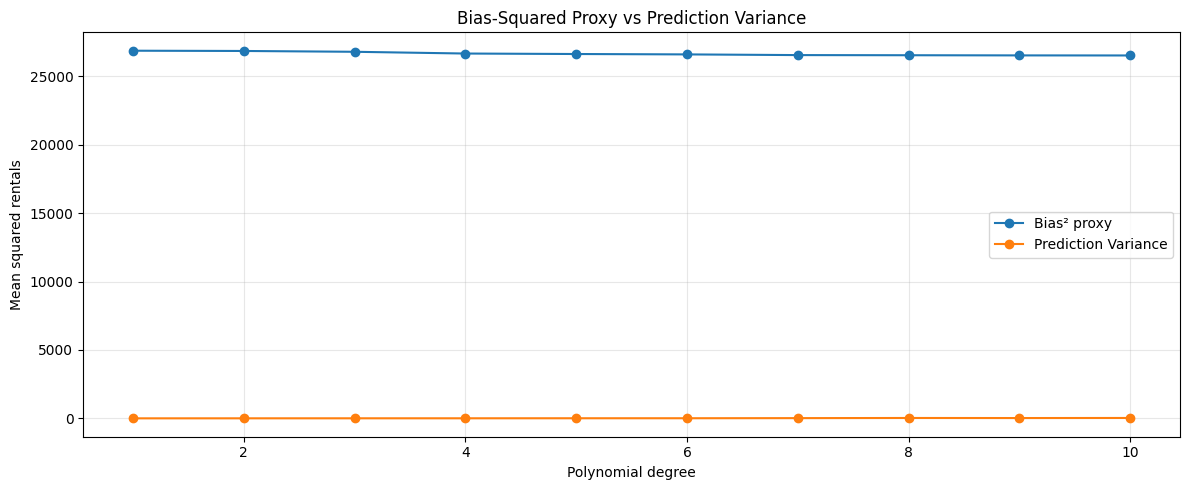

In [65]:
poly_df[
    ["Bias² proxy", "Prediction Variance"]
].plot(
    marker="o",
    figsize=(12, 5)
)

plt.xlabel("Polynomial degree")
plt.ylabel("Mean squared rentals")
plt.title("Bias-Squared Proxy vs Prediction Variance")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


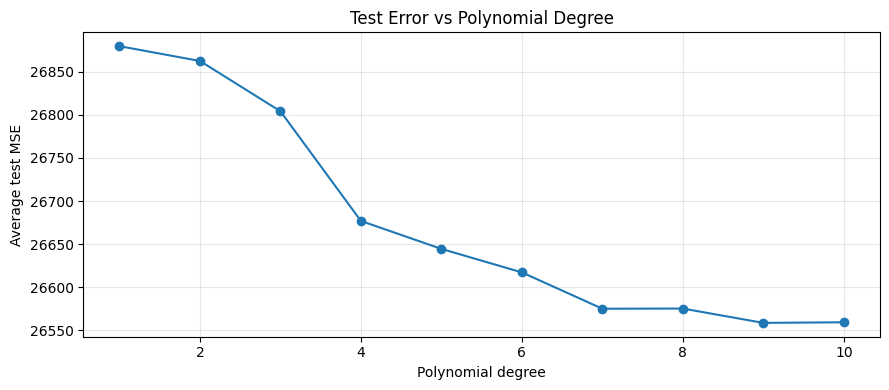

In [66]:
poly_df[
    ['Average Test MSE']
].plot(
    marker='o',
    legend=False,
    figsize=(9, 4)
)

plt.xlabel("Polynomial degree")
plt.ylabel("Average test MSE")
plt.title("Test Error vs Polynomial Degree")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



In [67]:

print("\nEXPERIMENT COMPLETE!")
print("Dataset: UCI Bike Sharing - hour.csv")
print("SLR feature: atemp")
print("MLR features: atemp, hum, windspeed")
print("Bootstrap repetitions: 100")
print("Polynomial degrees:", degrees)
print("\nNote: Bias² proxy uses observed test targets.")
print("It is NOT the exact theoretical bias² because")
print("the true underlying bike-rental function is unknown.")



EXPERIMENT COMPLETE!
Dataset: UCI Bike Sharing - hour.csv
SLR feature: atemp
MLR features: atemp, hum, windspeed
Bootstrap repetitions: 100
Polynomial degrees: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

Note: Bias² proxy uses observed test targets.
It is NOT the exact theoretical bias² because
the true underlying bike-rental function is unknown.
